In [15]:
import numpy as np
from pathlib import Path
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, OS_model, k_risk

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc
import seaborn as sns

# Loading all pre-saved data

In [40]:
### PROVIDE scenarios 
# Robin Lamboll, Joeri Rogelj, & Carl-Friedrich Schleussner. (2025). 
    # Scenario emissions and temperature data for PROVIDE project (v1.3.0) [Data set]. 
    # Zenodo. https://doi.org/10.5281/zenodo.11108741
# https://pure.iiasa.ac.at/id/eprint/18130/1/essoar.10511875.2.pdf for description
# https://zenodo.org/records/11108741 for actual data set

folder = '../../Data/PROVIDE 2025/'
cols = list(pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',nrows=1))
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
# df=df.rename(columns={'scenario':''})
scenarios = df.columns.values

### GTPR 2025
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
df_TEs[['Threshold (°C) – Min.', 
        'Threshold (°C) – Est.', 
        'Threshold (°C) – Max.']] = df_TEs[['Threshold (°C) – Min.', 
                                            'Threshold (°C) – Est.', 
                                            'Threshold (°C) – Max.']].interpolate(method='linear', axis=1, limit_direction='backward')
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

### Pre-generated interaction matrices from Wunderling 2024
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/Wunderling 2024/A_%s.csv'%r) for r in range(len_sample)]

In [14]:
df_TEs.loc['PERM']

Tipping element                                    Boreal permafrost collapse
Collapse (years)                                                           50
Recovery (years)                                                          500
Threshold (°C) – Min.                                                     3.0
Threshold (°C) – Est.                                                     4.0
Threshold (°C) – Max.                                                     6.0
Beta (1/°C)                                                          6.906755
Max Impact (°C) – Global                                                  0.3
Comments                    From Armstrong McKay 2022 max impact is estima...
Name: PERM, dtype: object

## Fitting OS_model to a baseline PROVIDE scenario

In [5]:
scenarios

array(['CurPol_SAP', 'CurPol_OS_1.5C', 'ModAct_OS_1.5C', 'ModAct_OS_1C',
       'ModAct_SAP', 'ssp534-over', 'Neg_SAP', 'GS_NZGHG', 'Ren_NZCO2',
       'Neg_NZGHG', 'Ref_1p5', 'Neg_OS_0C', 'LD_NZGHG', 'SP_NZGHG',
       'ssp119'], dtype=object)

In [176]:
baseline = 'ssp119'#'CurPol_OS_1.5C'
baseline_disp = baseline#'SSP5-3.4-OS'
temp = df[baseline].to_numpy()
t_ref=2015
T_ref=temp[t_ref-1850]
T_max=temp.max()
xdata = np.arange(t_ref,2301)-t_ref
ydata=temp[t_ref-1850:]
popt, pcov = curve_fit(OS_model, xdata, ydata,
                       p0=[T_ref, T_max, temp[-1], (T_max-T_ref)/0.01, 10 ,(temp.max()-T_ref)/0.01],
                       bounds = ([T_ref-0.5, T_max-0.5, temp[-1]-0.5, 10, 0, 10],
                                 [T_ref+0.5, T_max+0.5, temp[-1]+0.5, len(ydata), 100, len(ydata)]) )

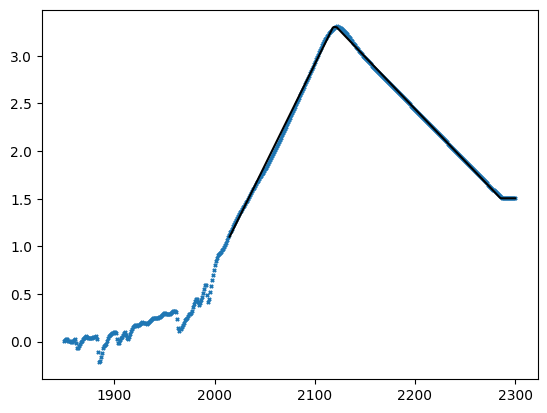

In [167]:
plt.scatter(np.arange(1850,1850+len(temp)),temp,marker='x',s=5)
plt.plot(xdata+t_ref,OS_model(xdata,*popt),c='k')

In [32]:
1850+len(temp)

2301

## Fitting OS_model to SSP1-2.6 (not from PROVIDE)

In [198]:
df_ipcc = pd.read_excel('../../Data/extendedSSPs.xlsx')
baseline='ssp126'
baseline_disp=baseline
scenarios_ipcc = df_ipcc['scenario'].unique()
# dfs = {s: df[df['scenario']==s].set_index('quantile').iloc[:,9:].transpose() for s in scenarios}
# print(scenarios_ipcc)
df_ssp126 = df_ipcc[df_ipcc['scenario']=='ssp126'].set_index('quantile').iloc[:,9:].transpose()['median']
df_ssp126.head()

1850-07-01 00:00:00   -0.042477
1851-07-01 00:00:00   -0.011424
1852-07-01 00:00:00   -0.008641
1853-07-01 00:00:00   -0.011269
1854-07-01 00:00:00   -0.030521
Name: median, dtype: float64

In [188]:
temp = df_ssp126.to_numpy()
t_ref=2015
T_ref=temp[t_ref-1850]
T_max=temp.max()
xdata = np.arange(t_ref,1850+len(temp))-t_ref
ydata=temp[t_ref-1850:]
popt, pcov = curve_fit(OS_model, xdata, ydata,
                       p0=[T_ref, T_max, temp[-1], (T_max-T_ref)/0.01, 10 ,(temp.max()-T_ref)/0.01],
                       bounds = ([T_ref-0.5, T_max-0.5, temp[-1]-0.5, 10, 0, 10],
                                 [T_ref+0.5, T_max+0.5, temp[-1]+0.5, len(ydata), 100, len(ydata)]) )

# Simulations

## Set-up

In [189]:
T_0s = np.arange(0,5.1,step=0.1)
T_peaks = np.arange(0,5.1,step=0.1)
T_oss = np.arange(0,5.1,step=0.1)

t_ups = np.arange(0,201,step=10)
t_plats = np.arange(0,201,step=10)
t_downs = np.arange(0,201,step=10)

pars = [T_0s, T_peaks, T_oss, t_ups, t_plats, t_downs]

years = xdata+t_ref
no_years=len(years)

pcs = [np.ones((len(p),no_years,len(df_TEs)))*q_c.reshape((1,1,len(df_TEs))) for p in pars]
prs = [np.ones((len(p),no_years,len(df_TEs)))*q_r.reshape((1,1,len(df_TEs))) for p in pars]

temps = [np.zeros((len(pars[i]),no_years)) for i in range(len(popt))]
for i in range(len(popt)):
    PAR = np.copy(popt)
    for j,p_j in enumerate(pars[i]):
        PAR[i] = p_j
        temps[i][j,:] = OS_model(xdata,*PAR)
        for t in range(no_years):
            pcs[i][j,t,:] *= temp_response(temps[i][j,t], T_lim, betas)
            prs[i][j,t,:] *= 1-temp_response(temps[i][j,t], T_lim, betas)

C:\Users\baraj\Documents\Code\NMaCh-TP\Code\Notebooks\..\util\overshoots.py:180: RuntimeWarning: invalid value encountered in divide
  out = T_0 + t[t<=t_up]*(T_peak-T_0)/t_up


## Baseline simulation

In [190]:
years = np.arange(1850,1850+len(temp))
no_years = len(years)

# Modifying collapse probabilities for each year according to each scenario
p_c = np.ones((no_years,len(df_TEs)))
p_c *= q_c

p_r = np.ones((no_years,len(df_TEs)))
p_r *= q_r

for t in range(no_years):
    p_c[t,:] *= temp_response(temp[t], T_lim, betas)
    p_r[t,:] *= (1-temp_response(temp[t], T_lim, betas))

D_baseline = np.zeros((len_sample,len(df_TEs),no_years))
for r in tqdm.tqdm(range(len_sample)):
    for t in range(1,no_years):
        D_baseline[r,:,t] = environmental_update(D_baseline[r,:,t-1],A[r],pc=p_c[t,:],pr=p_r[t,:])

100%|███████████████████████████████████████████████████████████████████████████████| 500/500 [00:03<00:00, 130.65it/s]


In [179]:
p_c.shape

(451, 9)

## Historical data up to 2015 for burn in

In [191]:
years_burn_in = np.arange(1850,2016) # up to and including 2015
no_burn_years = len(years_burn_in)
pc_burn = np.ones((no_burn_years,len(df_TEs)))
pc_burn *= q_c
pr_burn = np.ones((no_burn_years,len(df_TEs)))
pr_burn *= q_r
for t in years_burn_in-1850:
    pc_burn[t,:] *= temp_response(temp[t], T_lim, betas)
    pr_burn[t,:] *= (1-temp_response(temp[t], T_lim, betas))

D_burn = np.zeros((len_sample,len(df_TEs)))
D_burn_noint = np.zeros(len(df_TEs))

for r in tqdm.tqdm(range(len_sample)):
    for t in range(1,no_burn_years):
        D_burn[r,:] = environmental_update(D_burn[r,:],
                                           A[r],
                                           pc=pc_burn[t,:],
                                           pr=pr_burn[t,:])
for t in tqdm.tqdm(range(1,no_burn_years)):
    D_burn_noint = environmental_update(D_burn_noint,
                                        np.zeros((len(df_TEs),len(df_TEs))),
                                        pc=pc_burn[t,:],
                                        pr=pr_burn[t,:])

100%|█████████████████████████████████████████████████████████████████████████████| 165/165 [00:00<00:00, 23598.86it/s]


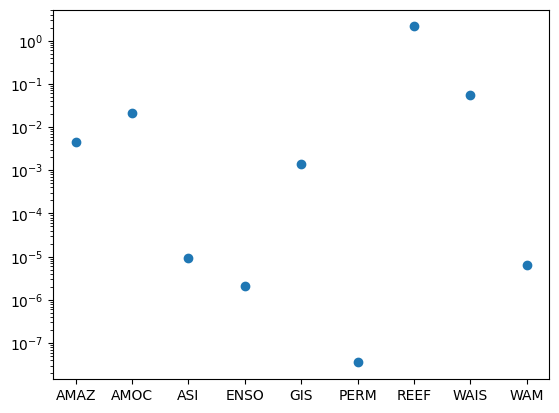

In [59]:
plt.scatter(df_TEs.index.values,D_burn.mean(axis=0)*100)
plt.yscale('log')

## Simulations for 2015 onwards

In [53]:
D_burn.shape

(500, 9)

In [192]:
years = np.arange(2015,1850+len(temp))
no_years=len(years)
D = [np.zeros((len(pars[i]),len_sample,len(df_TEs),no_years)) for i in range(len(popt))]
D_noint = [np.zeros((len(pars[i]),len(df_TEs),no_years)) for i in range(len(popt))]

for i in range(len(popt)):
    for r in range(len_sample):
        D[i][:,r,:,0] = D_burn[r,:]
    D_noint[i][:,:,0] = D_burn_noint[:]

for i in range(len(popt)):
    for j in tqdm.tqdm(range(len(pars[i]))):
        for t in range(1,no_years):
            D_noint[i][j,:,t] = environmental_update(D_noint[i][j,:,t-1],
                                                     np.zeros((len(df_TEs),len(df_TEs))),
                                                     pc=pcs[i][j,t,:],pr=prs[i][j,t,:])
            for r in range(len_sample):
                D[i][j,r,:,t] = environmental_update(D[i][j,r,:,t-1],A[r],
                                                     pc=pcs[i][j,t,:],pr=prs[i][j,t,:])

100%|██████████████████████████████████████████████████████████████████████████████████| 21/21 [00:52<00:00,  2.52s/it]


## Post-simulation analysis (calculating 1-risk)

In [193]:
D_noreef = [np.delete(D[i],6,axis=-2) for i in range(len(popt))]
AR_popt = [k_risk(D_noreef[i],1,axis=2)  
           for i in tqdm.tqdm(range(len(popt)))]

D_nr_noint = [np.delete(D_noint[i],6,axis=-2) for i in range(len(popt))]
AR_popt_noint = [k_risk(D_nr_noint[i],1,axis=1) 
                 for i in tqdm.tqdm(range(len(popt)))]

D_nr_baseline = np.delete(D_baseline,6,axis=1)
AR_baseline = k_risk(D_nr_baseline,1,axis=1)

100%|████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:00<00:00, 54.22it/s]


## provide ensemble

In [49]:
def OS_fit(xdata,ydata):
    return curve_fit(OS_model, xdata, ydata,
                       p0=[ydata[0], ydata.max(), ydata[-1], 
                           xdata[np.argmax(ydata)], 10 , (xdata[-1]-xdata[np.argmax(ydata)])/2],
                       bounds = ([ydata[0]-0.5, ydata.max()-0.5, ydata[-1]-0.5, 
                                  0, 0, 0],
                                 [ydata[0]+0.5, ydata.max()+0.5, ydata[-1]+0.5, 
                                  len(xdata), 100, len(xdata)]))

In [51]:
baseline = 'ssp534-over'#'CurPol nz 2120 decline -23800'
folder_ensemble = '../../Data/PROVIDE 2025/fair_temperatures/'
df_ensemble = pd.read_csv(folder_ensemble+'scen_%s.csv'%baseline)
df_ensemble=df_ensemble.set_index('year')
years_ensemble = df_ensemble.index.values
temps_ensemble=df_ensemble.to_numpy()

## only for curpol nz ..., since curpol_os_1.5C is NOT exactly the same as curpol nz 2120 ...
    # this is to make sure stabilisation temp are consistent
# temps_ensemble[2287-1850:,:] = temp[2287-1850:].reshape(14,1)

t_ref = 2015
xdata=years_ensemble[t_ref-1850:]-t_ref
popts = np.array([OS_fit(xdata,temps_ensemble[t_ref-1850:,r])[0] for r in range(temps_ensemble.shape[1])])
popt_of_m,_ = OS_fit(xdata,np.median(temps_ensemble[t_ref-1850:,:],axis=1))

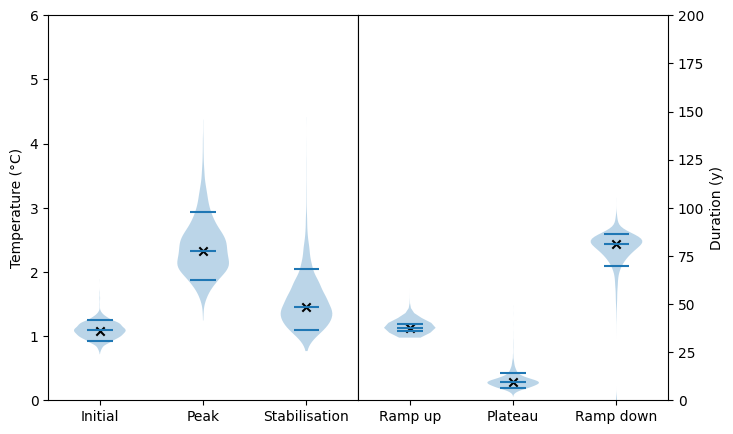

In [52]:
fig,axs=plt.subplots(figsize=(8,5),ncols=2,sharex=False,sharey=False)
fig.subplots_adjust(wspace=0.0)
axs[1].yaxis.set_label_position("right")
axs[1].yaxis.tick_right()

pm=np.median(popts,axis=0)
axs[0].set_xlim(-0.5,2.5)
# axs[0].errorbar(np.arange(3),pm[:3],
#                 yerr=np.abs(np.array([np.quantile(popts[:,:3],q,axis=0) for q in [0.1,0.9]])-pm[:3]),
#                 capsize=5,ls='',marker='x',ms=12)
axs[0].violinplot(popts[:,:3],positions=np.arange(3),showmedians=True,
                  quantiles=[[0.1,0.9]]*3,showextrema=False)
axs[0].set_xticks(np.arange(3),labels=['Initial','Peak','Stabilisation'])
axs[0].set_ylabel('Temperature (°C)')
axs[0].scatter(np.arange(3),popt[:3],marker='x',c='k')
axs[0].set_ylim(0,6)
axs[1].set_ylim(0,200)
# axs[0].errorbar()

axs[1].set_xlim(-0.5,2.5)
# axs[1].errorbar(np.arange(3),pm[3:],
#                 yerr=np.abs(np.array([np.quantile(popts[:,3:],q,axis=0) for q in [0.1,0.9]])-pm[3:]),
#                 capsize=5,ls='',marker='x',ms=12)
axs[1].violinplot(popts[:,3:],positions=np.arange(3),
                  showmedians=True,showextrema=False,quantiles=[[0.1,0.9]]*3)
axs[1].set_xticks(np.arange(3),labels=['Ramp up','Plateau','Ramp down'])
axs[1].set_ylabel('Duration (y)')
axs[1].scatter(np.arange(3),popt_of_m[3:],marker='x',c='k')
# fig.savefig('../../Figures/Overshoots/Conference/%s_parameter_dist.png'%baseline,bbox_inches='tight')

In [47]:
temps_ensemble.shape

(451, 2237)

(2287.0, 2300.0)

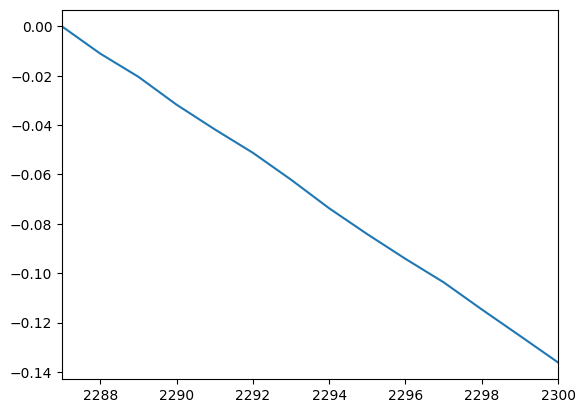

In [55]:
# plt.plot(years,temp[t_ref-1850:])
plt.plot(years,np.median(temps_ensemble,axis=1)[t_ref-1850:]-temp[t_ref-1850:])
plt.xlim(2287,2300)

# Plotting

## SOS

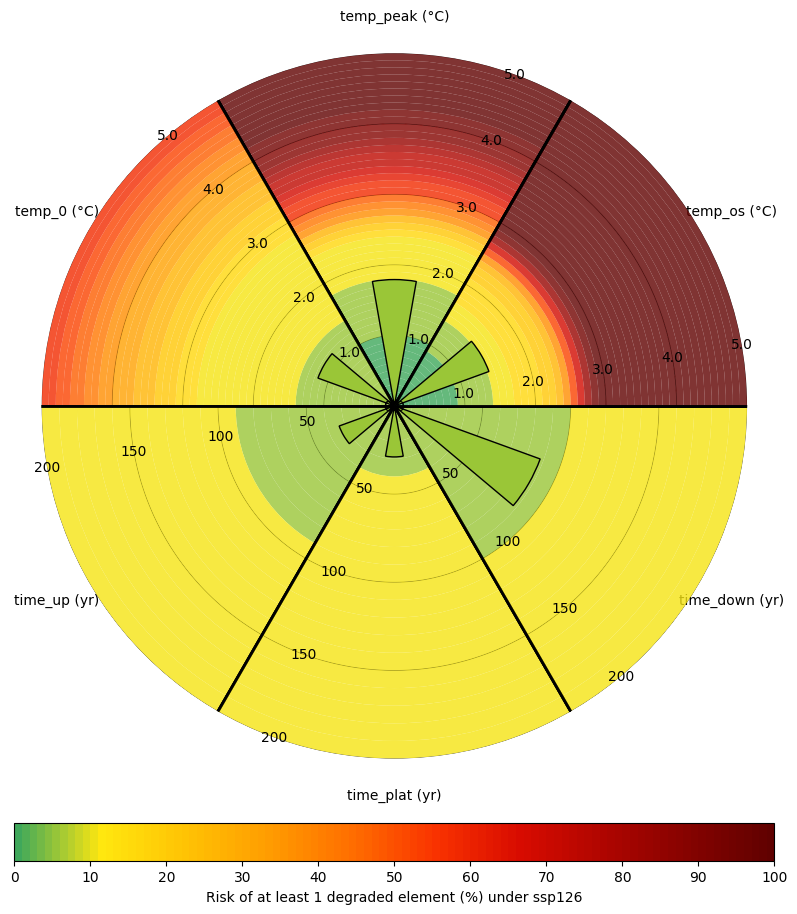

In [199]:
plotting='AR'
# baseline_disp='ssp1-2.6'

titles = ['temp_peak (°C)', 'temp_0 (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)', 'temp_os (°C)']
rticks = [np.arange(0,5.1,step=1), np.arange(0,5+.1,step=1),
           np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,5+.1,step=1)]
ylims=[(0,5), (0,5), (0,200), (0,200), (0,200), (0,5)]
N=len(popt)
outer_width = 360/N
inner_width = 2*180/3/N
width = outer_width+inner_width

fig=plt.figure(figsize=(8,9))
radar = Radar(fig, N, titles=titles, rotate_labels=False, 
              wedge_width = outer_width, with_rlabels=True, 
              ylims=ylims, rticks=rticks,loc_offset=10,wedgetick_lw=2)

sim2ax_reorder = [1,0,3,4,5,2]
AR_popt_reordered = list(map(AR_popt.__getitem__, sim2ax_reorder))
pars_reordered = list(map(pars.__getitem__,sim2ax_reorder))

colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=100)
# bounds = np.arange(-0.5,9,step=1)
# norm = mpl.colors.BoundaryNorm(bounds, cmap.N)

for j, ax, angle, pr, p_val in zip(range(len(popt)), 
                            radar.axes, 
                            radar.angles,
                            pars_reordered,
                            popt[sim2ax_reorder]):
    # to_plot = AR_popt_reordered[j].mean(axis=1).max(axis=1) # Picking out the maximum 1-risk
    if plotting == 'AR':
        to_plot = AR_popt_reordered[j].mean(axis=1)[:,2300-t_ref] # Picking out the final 1-risk
        to_plot_baseline = AR_baseline.mean(axis=0)[2300-t_ref]
    else:
        to_plot = D[sim2ax_reorder[j]].sum(axis=2).mean(axis=1)[:,-1]/9
        to_plot_baseline = D_baseline.sum(axis=1).mean(axis=0)[-1]/9
    radar.wedge_stacked_bar(ax,angle,pr,
                            c_list=c_list,zorder=0,
                            c_vals=to_plot,N_col_bins=20,alpha=0.8,edgecolor=None)
    radar.wedge_stacked_bar(ax,angle,[p_val],
                            c_list=c_list,
                            width=np.deg2rad(inner_width),
                            alpha=1,edgecolor='k',zorder=2,N_col_bins=20,
                            c_vals=[to_plot_baseline])
    
    # popt_en_med = np.median(popts[:,sim2ax_reorder[j]])
    # yerr = np.array([popt_en_med-np.quantile(popts[:,sim2ax_reorder[j]],0.1),
    #                   np.quantile(popts[:,sim2ax_reorder[j]],0.9)-popt_en_med]).reshape(2,1)
    # ax.errorbar(np.deg2rad(angle),popt_en_med, 
    #             yerr=yerr,
    #             c='k',ls='',capsize=7, fmt="x",lw=0.5,capthick=0.5)


radar.draw_wedgeticks(ylims=ylims,width=radar.wedge_width,lw=2)

fig.subplots_adjust(bottom=0.2)
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap),
                    ax=radar.axes,orientation='horizontal',
                    fraction=0.1,pad=0.075,label=r'Risk of at least 1 degraded element (%) under '+baseline_disp,alpha=0.8,
                    )
cbar.set_ticks([k for k in np.arange(0,1.1,0.1)],labels=[k for k in range(0,110,10)])
# rect = mpl.patches.Rectangle((nb-0.5, 0), 1, 1, linewidth=2, edgecolor='k', facecolor='none')
# cbar.ax.add_patch(rect)
# cbar.ax.set_xticks([(i+1)/len()])

folder='../../Figures/Overshoots/perturb_around_baseline/'
# fig.savefig(folder+'abrupt_thaw_sos_%s.png'%baseline,bbox_inches='tight')
fig.savefig('../../Figures/Overshoots/NCC/SOS_%s.png'%baseline_disp,bbox_inches='tight')

## Alternative visualisation

In [195]:
AR_temp = np.array([AR_popt[i] for i in range(3)])
AR_dura = np.array([AR_popt[i] for i in range(3,6)])
# AR_temp.shape

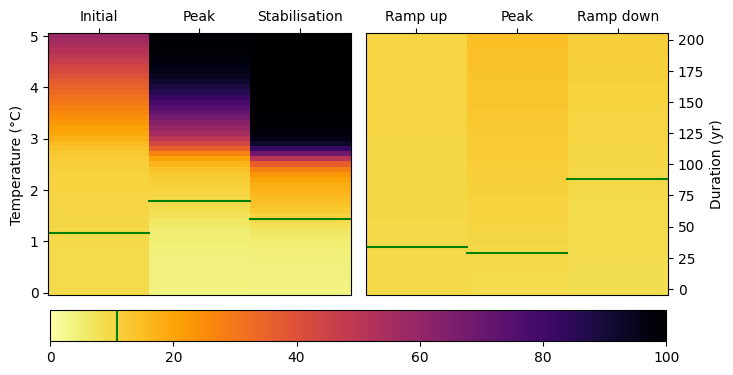

In [200]:
colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = 'inferno_r'#LinearSegmentedColormap.from_list('my_cmap', c_list, N=100)
baseline_col = 'green'

fig,axs = plt.subplots(ncols=2,figsize=(8,4))
fig.subplots_adjust(wspace=0.05)

for i in range(2):
    axs[i].xaxis.tick_top()
    # axs[i].grid(axis='y')
# axs[0].set_ylim(0,5)
# axs[1].set_ylim(0,200)

axs[0].set_ylabel("Temperature (°C)")
axs[0].set_xticks([0,1,2],[r'Initial', r'Peak', r'Stabilisation'])
axs[0].imshow(100*AR_temp.mean(axis=2)[:,:,2300-t_ref].T,aspect='auto',origin='lower',
                 cmap=cmap,extent=(-0.5, 3-0.5, -.05, T_peaks.max()+0.05),vmin=0,vmax=100)

axs[1].yaxis.tick_right()
axs[1].set_ylabel("Duration (yr)")
axs[1].yaxis.set_label_position("right")
axs[1].set_xticks([0,1,2],[r'Ramp up', r'Peak', r'Ramp down'])
im=axs[1].imshow(100*AR_dura.mean(axis=2)[:,:,2300-t_ref].T,aspect='auto',origin='lower',
                 cmap=cmap,extent=(-0.5, 3-0.5, -5, t_ups.max()+5),vmin=0,vmax=100)
# fig.colorbar()

for i in range(6):
    axs[i//3].plot([i%3-0.5,i%3+0.5],[popt[i]]*2,c=baseline_col)
cb = fig.colorbar(im, ax=axs, orientation='horizontal', fraction=.1,pad=.05)
cb.ax.plot([AR_baseline.mean(axis=0)[-1]*100]*2,[0,1],c=baseline_col)

fig.savefig('../../Figures/Overshoots/NCC/SOS_alt_%s.png'%baseline,bbox_inches='tight')

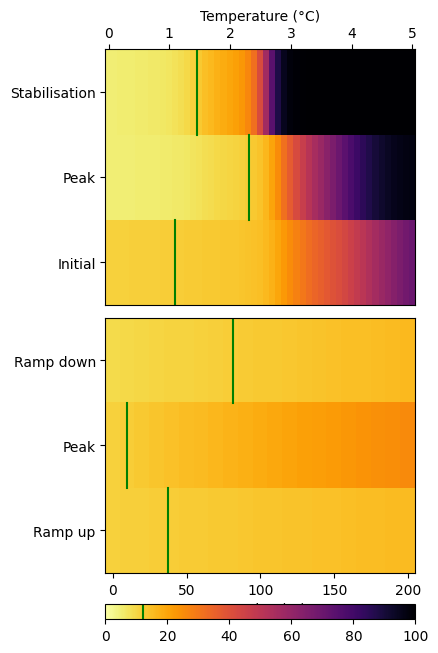

In [154]:
colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = 'inferno_r' #LinearSegmentedColormap.from_list('my_cmap', c_list, N=100)
baseline_col = 'green'

fig,axs = plt.subplots(nrows=2,figsize=(4,8))
fig.subplots_adjust(hspace=0.05)

# for i in range(2):
#     axs[i].xaxis.tick_top()
#     axs[i].grid(axis='y')

axs[0].xaxis.tick_top()
axs[0].xaxis.set_label_position("top")
axs[0].set_xlabel("Temperature (°C)")
axs[0].set_yticks([0,1,2],[r'Initial', r'Peak', r'Stabilisation'])
axs[0].imshow(100*AR_temp.mean(axis=2)[:,:,-1],aspect='auto',origin='lower',
                 cmap=cmap,extent=(-.05, T_peaks.max()+0.05, -0.5, 3-0.5),vmin=0,vmax=100)
for i in range(6):
    axs[i//3].plot([popt[i]]*2,[i%3-0.5,i%3+0.5],c=baseline_col)

axs[1].set_xlabel("Duration (yr)")
axs[1].set_yticks([0,1,2],[r'Ramp up', r'Peak', r'Ramp down'])
im=axs[1].imshow(100*AR_dura.mean(axis=2)[:,:,-1],aspect='auto',origin='lower',
                 cmap=cmap,extent=(-5, t_ups.max()+5,-0.5, 3-0.5),vmin=0,vmax=100)
# fig.colorbar()

cb = fig.colorbar(im, ax=axs, fraction=.1,pad=.05,orientation='horizontal')
cb.ax.plot([AR_baseline.mean(axis=0)[-1]*100]*2,[0,1],c=baseline_col)

In [123]:
popt

array([  1.10009253,   3.30206669,   1.50422   , 103.28176735,
         3.4404387 , 163.72772026])

In [120]:
for i in range(6):
    print(i%3)

0
1
2
0
1
2


In [96]:
T_peaks

array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.1, 1.2,
       1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2. , 2.1, 2.2, 2.3, 2.4, 2.5,
       2.6, 2.7, 2.8, 2.9, 3. , 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8,
       3.9, 4. , 4.1, 4.2, 4.3, 4.4, 4.5, 4.6, 4.7, 4.8, 4.9, 5. ])

In [87]:
AR_popt[0].shape

(51, 500, 286)

In [50]:
pars[-1].shape

(21,)

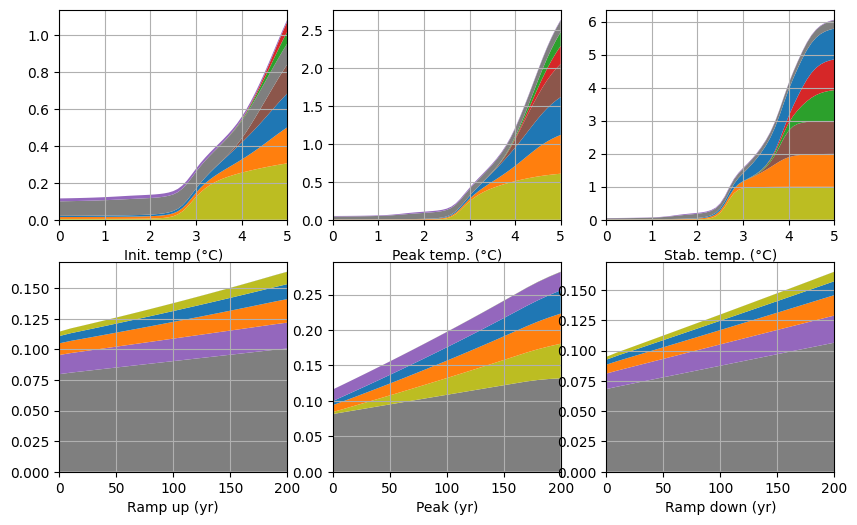

In [80]:
fig,axs=plt.subplots(figsize=(10,6),ncols=3,nrows=2,sharey=False)
titles = ['Init. temp (°C)', 'Peak temp. (°C)', 'Stab. temp. (°C)', 
          'Ramp up (yr)', 'Peak (yr)', 'Ramp down (yr)']
colors=np.array(plt.rcParams['axes.prop_cycle'].by_key()['color'])
for i in range(6):
    to_plot = np.delete(D[i],6,axis=-2).mean(axis=1)[:,:,-1]
    mask_sort = to_plot[-1,:].argsort()[::-1]
    axs[i//3,i%3].set_xlabel(titles[i])
    axs[i//3,i%3].set_xlim(pars[i][[0,-1]])
    axs[i//3,i%3].grid()
    # axs[i//3,i%3].plot(pars[i],to_plot.sum(axis=1))
    axs[i//3,i%3].stackplot(pars[i],to_plot[:,mask_sort].T,colors=np.delete(colors,6)[mask_sort])

## Looking at sensitivity of individual risks

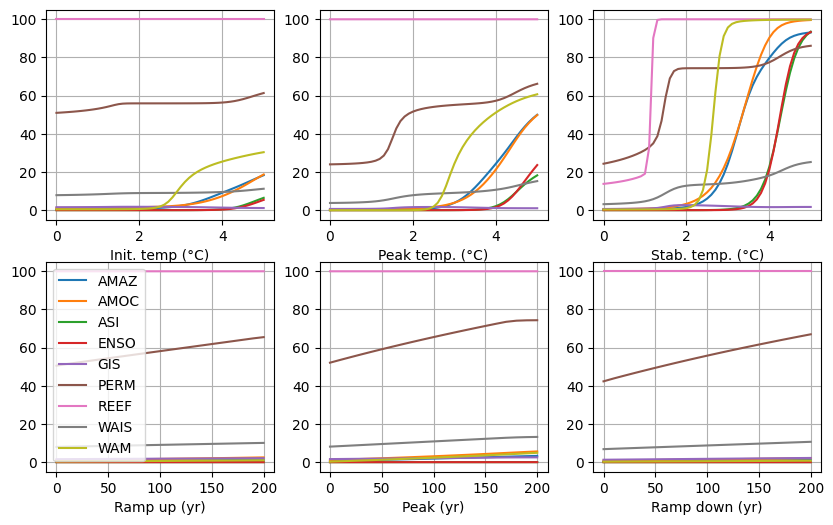

In [68]:
fig,axs=plt.subplots(figsize=(10,6),ncols=3,nrows=2)
titles = ['Init. temp (°C)', 'Peak temp. (°C)', 'Stab. temp. (°C)', 
          'Ramp up (yr)', 'Peak (yr)', 'Ramp down (yr)']
te_labels = df_TEs.index.values
# fig.subplots_adjust(hspace=0.05,wspace=0.05)

for i in range(6):
    axs[i//3,i%3].set_xlabel(titles[i])
    # axs[i//3,i%3].set_yscale('log')
    axs[i//3,i%3].grid()
    for j in range(9):
        axs[i//3,i%3].plot(pars[i],D[i][:,:,j,-1].mean(axis=1)*100,label=te_labels[j])
axs[1,0].legend()

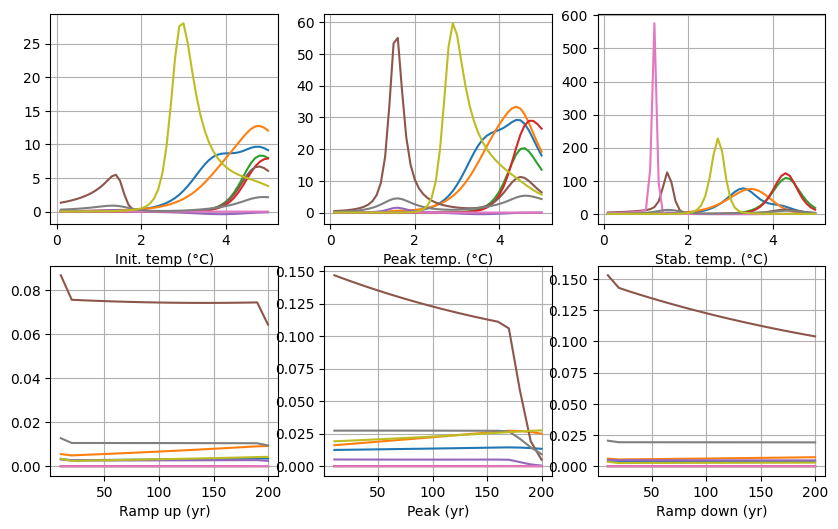

In [61]:
fig,axs=plt.subplots(figsize=(10,6),ncols=3,nrows=2)
titles = ['Init. temp (°C)', 'Peak temp. (°C)', 'Stab. temp. (°C)', 
          'Ramp up (yr)', 'Peak (yr)', 'Ramp down (yr)']
te_labels = df_TEs.index.values
# fig.subplots_adjust(hspace=0.05,wspace=0.05)

for i in range(6):
    axs[i//3,i%3].set_xlabel(titles[i])
    # axs[i//3,i%3].set_yscale('log')
    axs[i//3,i%3].grid()
    for j in range(9):
        axs[i//3,i%3].plot(pars[i][1:],np.diff(D[i][:,:,j,-1].mean(axis=1)*100)/np.diff(pars[i]),label=te_labels[j])

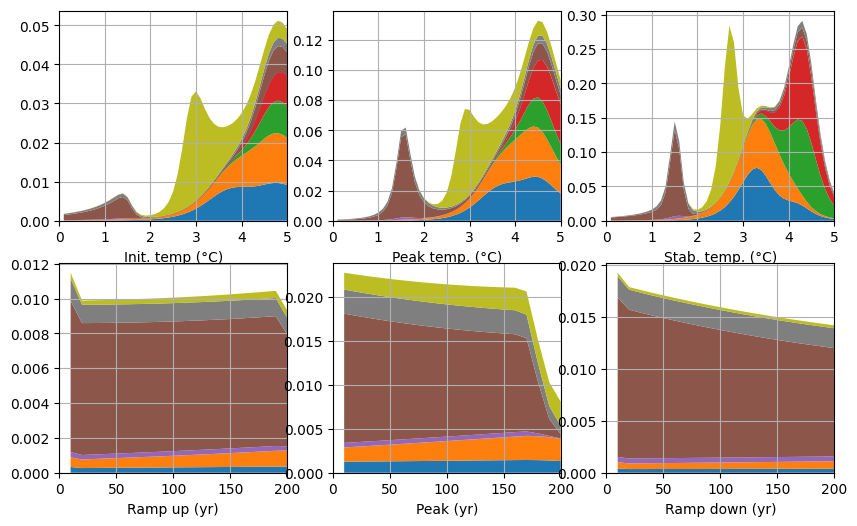

In [64]:
fig,axs=plt.subplots(figsize=(10,6),ncols=3,nrows=2,sharey=False)
titles = ['Init. temp (°C)', 'Peak temp. (°C)', 'Stab. temp. (°C)', 
          'Ramp up (yr)', 'Peak (yr)', 'Ramp down (yr)']
colors=np.array(plt.rcParams['axes.prop_cycle'].by_key()['color'])
for i in range(6):
    to_plot = np.diff(np.delete(D[i],6,axis=-2).mean(axis=1)[:,:,-1],axis=0)
    mask_sort = np.arange(8)#to_plot[-1,:].argsort()[::-1]
    axs[i//3,i%3].set_xlabel(titles[i])
    axs[i//3,i%3].set_xlim(pars[i][[0,-1]])
    axs[i//3,i%3].grid()
    # axs[i//3,i%3].plot(pars[i],to_plot.sum(axis=1))
    axs[i//3,i%3].stackplot(pars[i][1:],to_plot[:,mask_sort].T,colors=np.delete(colors,6)[mask_sort])

In [71]:
popt

array([ 1.08741336,  2.31898889,  1.45509682, 37.55081547,  9.41345856,
       81.42360068])

In [64]:
df_TEs.index.values

array(['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS',
       'WAM'], dtype=object)

In [65]:
D[0].shape

(51, 500, 9, 286)

In [40]:
for j, pr, p_val in zip(range(len(popt)), 
                            pars_reordered,
                            popt[sim2ax_reorder]):
    print(np.array([p_val-np.quantile(popts[:,sim2ax_reorder[j]],0.1),
                      np.quantile(popts[:,sim2ax_reorder[j]],0.9)-p_val]))

[0.69495059 0.93494759]
[0.16521909 0.16616058]
[5.73963518 3.89778846]
[ 3.18884096 14.92584718]
[-1.06218135 15.74566835]
[0.52490085 0.62341004]


In [34]:
print('popt',popt)
print('fitted to median', popt_of_m)
print('median of fitted parameters', np.median(popts,axis=0))

popt [  1.10009253   3.30206671   1.50422    103.28176816   3.44043629
 163.72772189]
fitted to median [  1.10009253   3.30206666   1.3835     103.28176581   3.24813601
 175.31878856]
median of fitted parameters [  1.09607745   3.29268805   1.38931368 102.84422596   4.06028038
 173.80837664]


In [43]:
print('10%', np.quantile(popts,0.1,axis=0))
print('popt',popt)
print('90%', np.quantile(popts,0.9,axis=0))

10% [  0.93487344   2.60711612   0.97931915  97.54213298   0.25159533
 164.78990324]
popt [  1.10009253   3.30206671   1.50422    103.28176816   3.44043629
 163.72772189]
90% [  1.26625311   4.2370143    2.12763004 107.17955662  18.36628347
 179.47339024]


In [29]:
popt_of_m

array([  1.10009253,   3.30206666,   1.3835    , 103.28176581,
         3.24813601, 175.31878856])

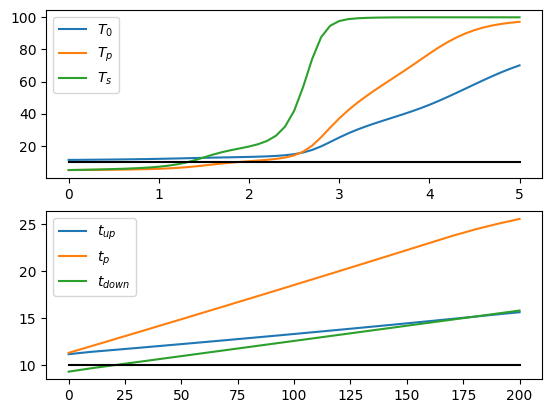

In [79]:
parameter_names = ['$T_0$', '$T_p$', '$T_s$', '$t_{up}$', '$t_{p}$', '$t_{down}$']

fig,axs=plt.subplots(nrows=2)
for i in range(6):
    axs[i//3].plot(pars[i], AR_popt[i].mean(axis=1)[:,-1]*100,label=parameter_names[i])
    axs[i//3].legend()

axs[0].plot([0,5], [10]*2,c='k')
axs[1].plot([0,200], [10]*2,c='k')

In [76]:
pars[i].shape

(21,)

In [69]:
print([i//3 for i in range(6)])

[0, 0, 0, 1, 1, 1]


In [15]:
AR_baseline.mean(axis=0)[-1]

np.float64(0.7383363436877759)

## comparisons against interaction-free

In [39]:
AR_popt_noint[0].shape

(51, 286)

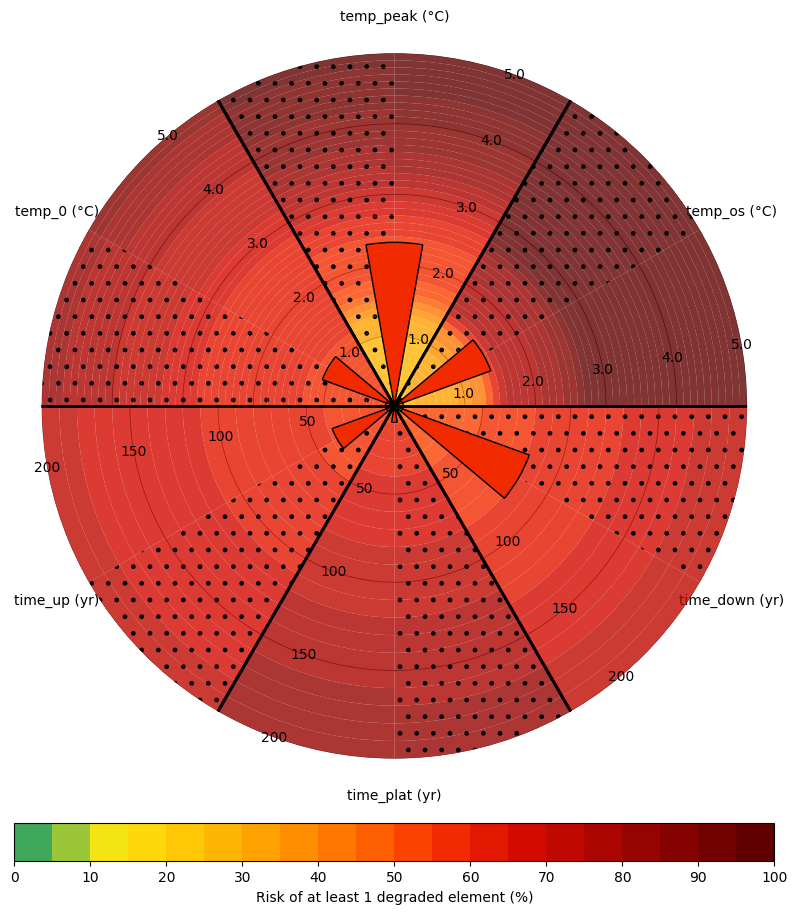

In [17]:
titles = ['temp_peak (°C)', 'temp_0 (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)', 'temp_os (°C)']
rticks = [np.arange(0,5.1,step=1), np.arange(0,5+.1,step=1),
           np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,5+.1,step=1)]
ylims=[(0,5), (0,5), (0,200), (0,200), (0,200), (0,5)]
N=len(popt)
outer_width = 360/N
inner_width = 2*180/3/N
width = outer_width+inner_width

fig=plt.figure(figsize=(8,9))
radar = Radar(fig, N, titles=titles, rotate_labels=False, 
              wedge_width = outer_width, with_rlabels=True, 
              ylims=ylims, rticks=rticks,loc_offset=10,wedgetick_lw=2)

sim2ax_reorder = [1,0,3,4,5,2]
AR_popt_reordered = list(map(AR_popt.__getitem__, sim2ax_reorder))
AR_popt_noint_reordered = list(map(AR_popt_noint.__getitem__, sim2ax_reorder))
pars_reordered = list(map(pars.__getitem__,sim2ax_reorder))

colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=20)


for j, ax, angle, pr in zip(range(len(popt)), 
                            radar.axes, 
                            radar.angles,
                            pars_reordered):
    to_plot = AR_popt_reordered[j].mean(axis=1)[:,-1]
    to_plot_noint = AR_popt_noint_reordered[j][:,-1]

    radar.wedge_stacked_bar(ax,angle-90/N,pr,
                            c_list=c_list,zorder=0,
                            c_vals=to_plot,N_col_bins=20,alpha=0.8,
                            edgecolor=None,width=np.deg2rad(outer_width/2))
    radar.wedge_stacked_bar(ax,angle+90/N,pr,
                            c_list=c_list,zorder=0,
                            c_vals=to_plot_noint,N_col_bins=20,alpha=0.8,
                            hatch='.',edgecolor=None,width=np.deg2rad(outer_width/2))
    radar.wedge_stacked_bar(ax,angle,[popt[sim2ax_reorder][j]],
                            c_list=c_list,
                            width=np.deg2rad(inner_width),
                            alpha=1,edgecolor='k',zorder=2,N_col_bins=20,
                            c_vals=[AR_baseline.mean(axis=0).max()])
radar.draw_wedgeticks(ylims=ylims,width=radar.wedge_width,lw=2)
fig.subplots_adjust(bottom=0.2)
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap),
                    ax=radar.axes,orientation='horizontal',
                    fraction=0.1,pad=0.075,label=r'Risk of at least 1 degraded element (%)',alpha=0.8,
                    )
cbar.set_ticks([k for k in np.arange(0,1.1,0.1)],labels=[k for k in range(0,110,10)])

## looking at speeds more specifically

/tmp/ipykernel_185775/1902881247.py:10: RuntimeWarning: divide by zero encountered in divide
  axs[0].scatter((popt[1]-popt[0])/pars[3],AR_popt[3][:,:,-1].mean(axis=1),label='Up duration')
/tmp/ipykernel_185775/1902881247.py:15: RuntimeWarning: divide by zero encountered in divide
  axs[1].scatter((popt[1]-popt[2])/pars[5],AR_popt[5][:,:,-1].mean(axis=1),label='Down duration')


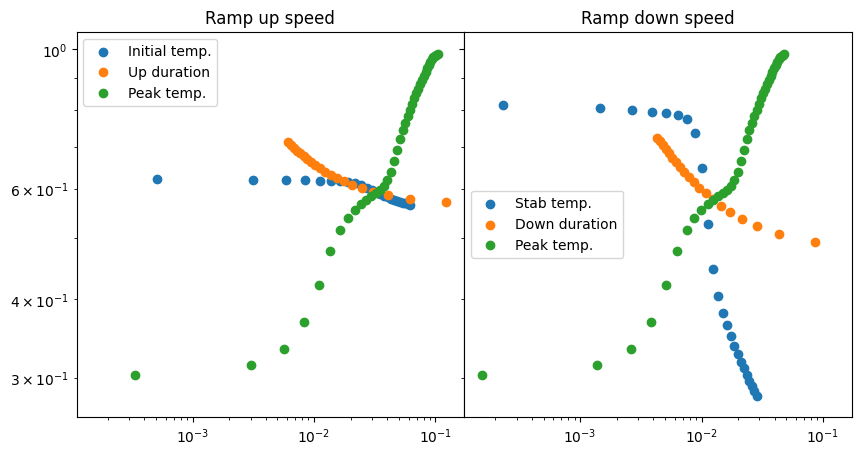

In [18]:
fig,axs=plt.subplots(ncols=2,figsize=(10,5),sharey=True,sharex=True)
fig.subplots_adjust(wspace=0)
axs[0].set_title('Ramp up speed')
# axs[1].set_title('Peak')
axs[1].set_title('Ramp down speed')
axs[0].set_xscale('log')
axs[0].set_yscale('log')

axs[0].scatter((popt[1]-pars[0])/popt[3],AR_popt[0][:,:,-1].mean(axis=1),label='Initial temp.')
axs[0].scatter((popt[1]-popt[0])/pars[3],AR_popt[3][:,:,-1].mean(axis=1),label='Up duration')
axs[0].scatter((pars[1]-popt[0])/popt[3],AR_popt[1][:,:,-1].mean(axis=1),label='Peak temp.')
axs[0].legend()

axs[1].scatter((popt[1]-pars[2])/popt[5],AR_popt[2][:,:,-1].mean(axis=1),label='Stab temp.')
axs[1].scatter((popt[1]-popt[2])/pars[5],AR_popt[5][:,:,-1].mean(axis=1),label='Down duration')
axs[1].scatter((pars[1]-popt[0])/popt[5],AR_popt[1][:,:,-1].mean(axis=1),label='Peak temp.')
axs[1].legend()

## looking at overshoot integral

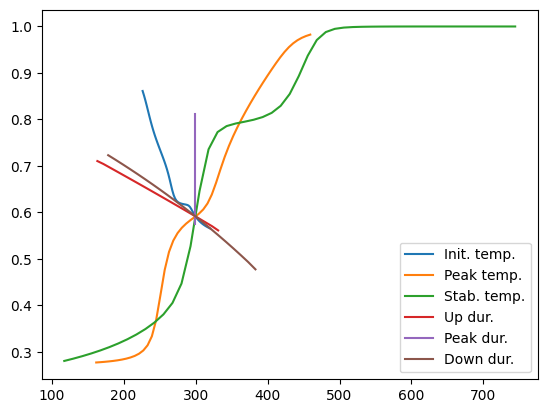

In [19]:
def OS_integral(p):
    return p[3]*(p[1]-p[0])/2 + p[2]*p[4] + p[5]*(p[1]-p[2])/2 + (2300-2015-p[3]-p[4]-p[5])*p[2]

p_labels=['Init. temp.', 'Peak temp.', 'Stab. temp.', 'Up dur.', 'Peak dur.', 'Down dur.']

fig,ax=plt.subplots()
for i in range(6):
    p = list(np.copy(popt))
    p[i]=pars[i]
    ax.plot(OS_integral(p),AR_popt[i][:,:,-1].mean(axis=1),label=p_labels[i])

ax.legend()

In [43]:
popt

array([  1.10009253,   3.30206671,   1.50422   , 103.28176816,
         3.44043629, 163.72772189])

## elementary one-at-a-time (OAT) sensitivity analysis

In [21]:
AR_popt[0].shape

(51, 500, 286)

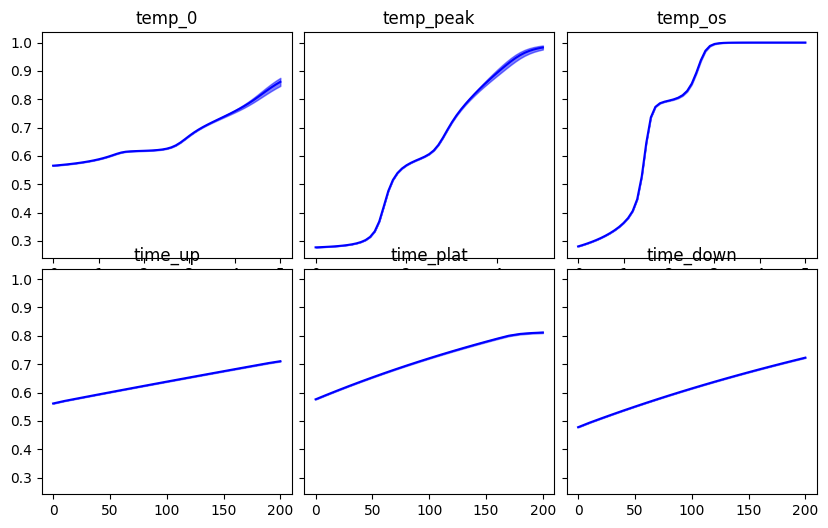

In [20]:
fig,axs=plt.subplots(figsize=(10,6),ncols=3,nrows=2,sharey=True)
par_files=['temp_0','temp_peak','temp_os',
             'time_up','time_plat','time_down'] 
fig.subplots_adjust(hspace=0.05,wspace=0.05)
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])
    mean=AR_popt[i].mean(axis=1)[:,-1]
    std=AR_popt[i].std(axis=1)[:,-1]
    axs[i//3,i%3].fill_between(pars[i],mean-std,mean+std,color='blue',alpha=0.5)
    axs[i//3,i%3].plot(pars[i],mean,color='blue')
    # for r in range(500):
    #     axs[i//3,i%3].scatter(pars[i],AR_popt[i][:,r,-1],c='k',s=5)

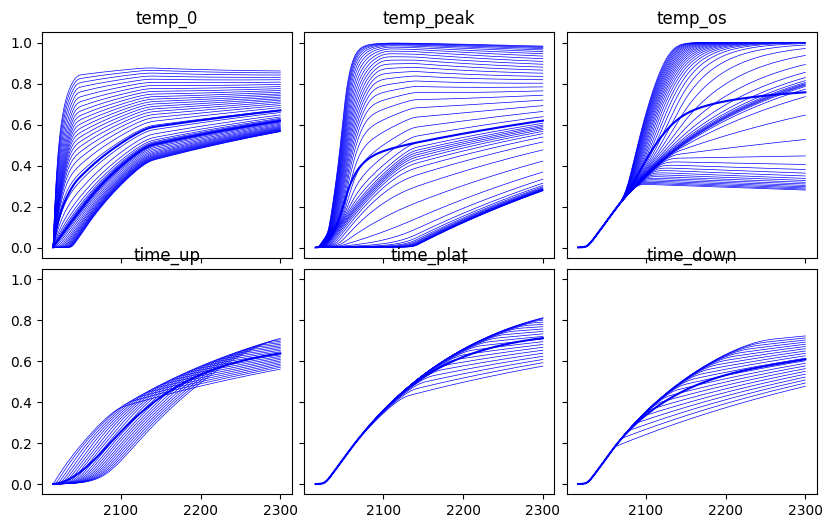

In [21]:
fig,axs=plt.subplots(figsize=(10,6),ncols=3,nrows=2,sharey=True,sharex=True)
par_files=['temp_0','temp_peak','temp_os',
             'time_up','time_plat','time_down'] 
fig.subplots_adjust(hspace=0.05,wspace=0.05)
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])
    mean=AR_popt[i].mean(axis=(0,1))
    std=AR_popt[i].std(axis=(0,1))
    # axs[i//3,i%3].fill_between(pars[i],mean-std,mean+std,color='blue',alpha=0.5)
    axs[i//3,i%3].plot(years,mean,color='blue')
    for r in range(AR_popt[i].shape[0]):
        axs[i//3,i%3].plot(years,AR_popt[i].mean(axis=1)[r,:],color='blue',lw=0.5)
    # for r in range(500):
    #     axs[i//3,i%3].scatter(pars[i],AR_popt[i][:,r,-1],c='k',s=5)

In [38]:
popt

array([ 1.08741336,  2.31898889,  1.45509682, 37.55081547,  9.41345856,
       81.42360068])

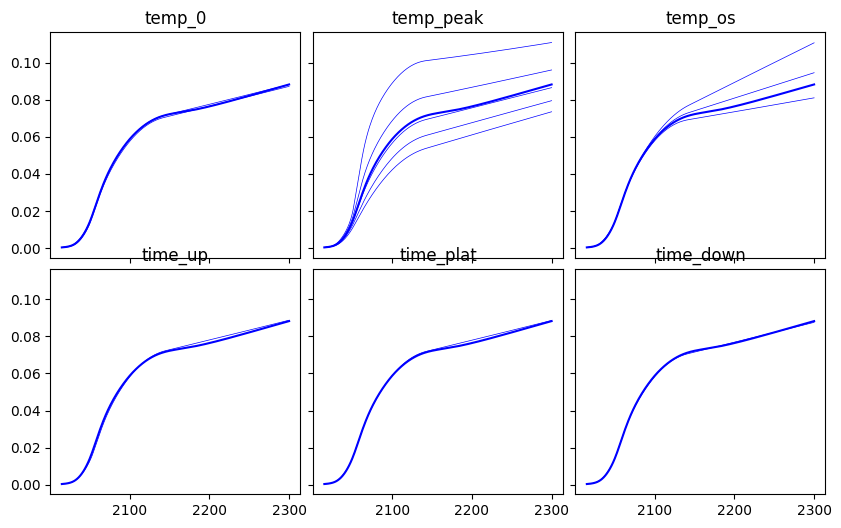

In [39]:
fig,axs=plt.subplots(figsize=(10,6),ncols=3,nrows=2,sharey=True,sharex=True)
par_files=['temp_0','temp_peak','temp_os',
             'time_up','time_plat','time_down'] 
fig.subplots_adjust(hspace=0.05,wspace=0.05)
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])
    # axs[i//3,i%3].fill_between(pars[i],mean-std,mean+std,color='blue',alpha=0.5)
    axs[i//3,i%3].plot(years,AR_baseline.mean(axis=0)[years[0]-1850:],color='blue')
    for r in range(AR_popt[i].shape[0]):
        if np.abs(pars[i][r]-popt[i])/popt[i] <= 0.1:
            axs[i//3,i%3].plot(years,AR_popt[i].mean(axis=1)[r,:],color='blue',lw=0.5)

## sos in temperature scenario

In [13]:
j=0
pars[j][AR_popt[j].mean(axis=1).max(axis=1)<=0.1].max()

np.float64(1.9000000000000001)

temp_0 0.0 1.9000000000000001
temp_peak 0.0 2.4000000000000004
temp_os 0.0 1.5
time_up 0.0 80.0
time_plat 0.0 20.0
time_down 0.0 110.0


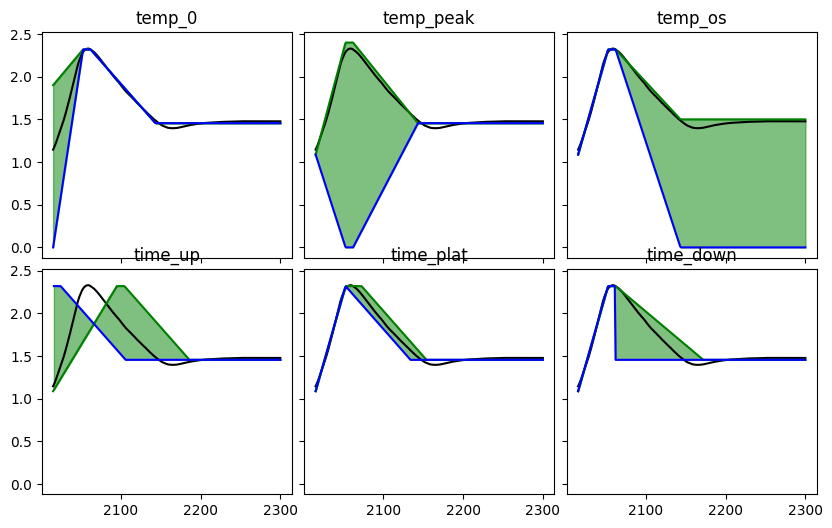

In [35]:
fig,axs=plt.subplots(figsize=(10,6),ncols=3,nrows=2,sharey=True,sharex=True)
par_files=['temp_0','temp_peak','temp_os',
             'time_up','time_plat','time_down'] 
fig.subplots_adjust(hspace=0.05,wspace=0.05)
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])
    axs[i//3,i%3].plot(years,temp[years[0]-1850:],color='k')

    PAR_max = np.copy(popt)
    PAR_min = np.copy(popt)
    PAR_max[i] = pars[i][AR_popt[i].mean(axis=1).max(axis=1)<=0.1].max()
    PAR_min[i] = pars[i][AR_popt[i].mean(axis=1).max(axis=1)<=0.1].min()
    print(par_files[i],PAR_min[i],PAR_max[i])
    axs[i//3,i%3].plot(years,OS_model(years-2015,*PAR_max),color='g')
    axs[i//3,i%3].plot(years,OS_model(years-2015,*PAR_min),color='b')
    axs[i//3,i%3].fill_between(years,
                               OS_model(years-2015,*PAR_min),
                               OS_model(years-2015,*PAR_max), color='green',alpha=0.5)

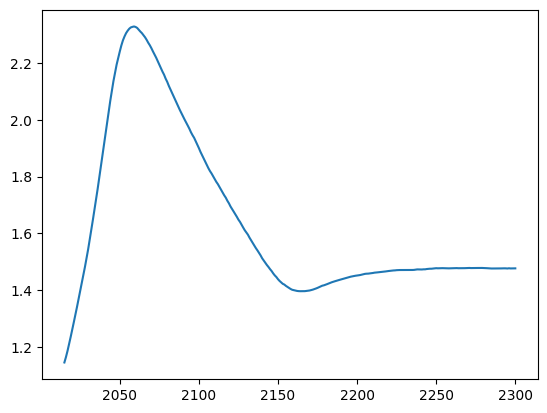

In [31]:
plt.plot(years,temp[years[0]-1850:])

## Poisson binomial pmf

In [10]:
from scipy.stats import poisson_binom

In [12]:
D[i].shape

(21, 500, 9, 286)

In [31]:
pmf = [np.array([[poisson_binom.pmf(k,D[i][j,:,:,-1].mean(axis=0)) 
                       for j in range(len(pars[i]))] 
                      for k in range(10)]) 
            for i in range(6)]

Text(0, 0.5, 'Number of tipped elements')

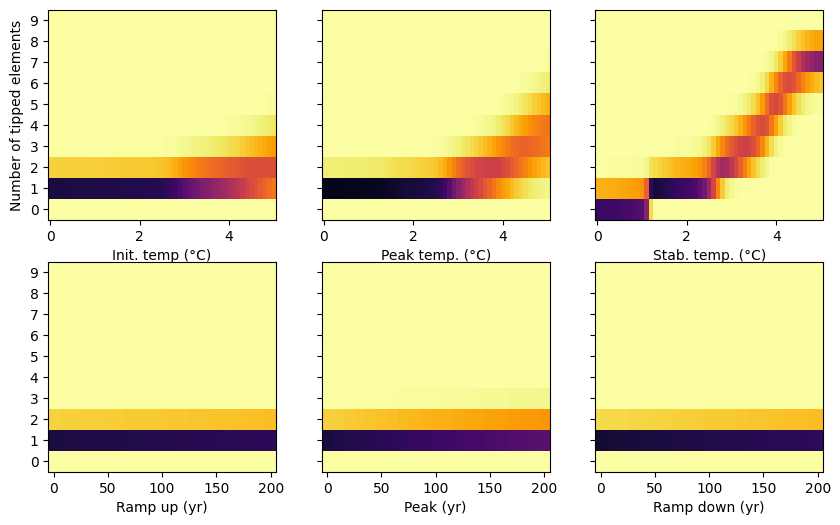

In [50]:
fig,axs=plt.subplots(figsize=(10,6),ncols=3,nrows=2,sharey=True)
titles = ['Init. temp (°C)', 'Peak temp. (°C)', 'Stab. temp. (°C)', 
          'Ramp up (yr)', 'Peak (yr)', 'Ramp down (yr)']
te_labels = df_TEs.index.values
# fig.subplots_adjust(hspace=0.05,wspace=0.05)

for i in range(6):
    axs[i//3,i%3].set_xlabel(titles[i])
    # axs[i//3,i%3].set_yscale('log')
    # axs[i//3,i%3].grid()
    im=axs[i//3,i%3].imshow(pmf[i],cmap='inferno_r',
                            aspect='auto',vmin=0,vmax=1,
                            origin='lower',
                            extent=(pars[i][0]-np.diff(pars[i])[0]/2, pars[i][-1]+np.diff(pars[i])[0]/2,
                                    -.5, 9.5) )
    # for j in range(10):
    #     axs[i//3,i%3].plot(pars[i],pmf[i][j,:]*100)
axs[0,0].set_yticks(np.arange(10),np.arange(10))
axs[0,0].set_ylabel('Number of tipped elements')
    # axs[1,0].legend()
# fig.colorbar(im)

In [58]:
D[i].mean(axis=1)[:,:,-1].T.shape

(9, 21)

Text(0, 0.5, 'Tipping elements')

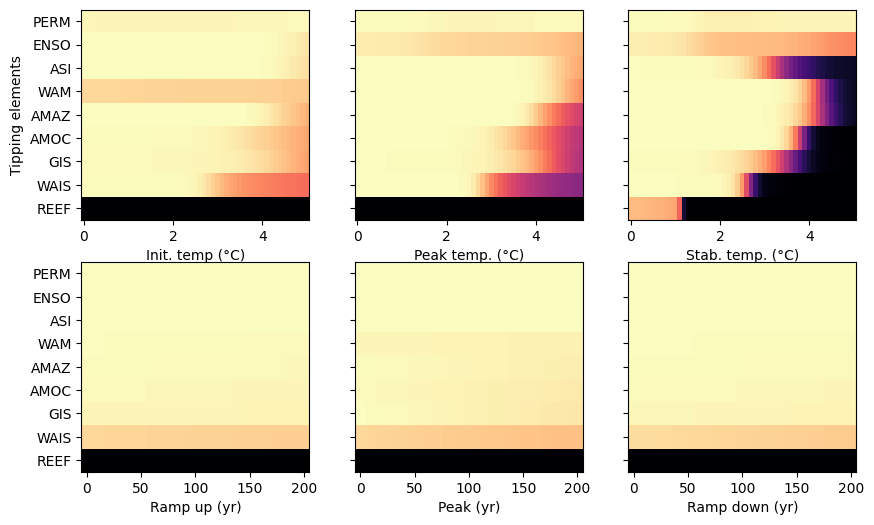

In [61]:
fig,axs=plt.subplots(figsize=(10,6),ncols=3,nrows=2,sharey=True)
titles = ['Init. temp (°C)', 'Peak temp. (°C)', 'Stab. temp. (°C)', 
          'Ramp up (yr)', 'Peak (yr)', 'Ramp down (yr)']
te_labels = df_TEs.index.values
# fig.subplots_adjust(hspace=0.05,wspace=0.05)

for i in range(6):
    axs[i//3,i%3].set_xlabel(titles[i])
    # axs[i//3,i%3].set_yscale('log')
    # axs[i//3,i%3].grid()
    to_plot=D[i].mean(axis=1)[:,:,-1].T*100
    mask_sort = to_plot[:,-1].argsort()
    im=axs[i//3,i%3].imshow(to_plot[mask_sort,:],cmap='magma_r',
                            aspect='auto',vmin=0,vmax=100,
                            origin='upper',
                            extent=(pars[i][0]-np.diff(pars[i])[0]/2, pars[i][-1]+np.diff(pars[i])[0]/2,
                                    8.5, -.5) )
    # for j in range(10):
    #     axs[i//3,i%3].plot(pars[i],pmf[i][j,:]*100)
axs[0,0].set_yticks(np.arange(9),df_TEs.index.values[mask_sort])
axs[0,0].set_ylabel('Tipping elements')
    # axs[1,0].legend()
# fig.colorbar(im)